# Smartphone skin-lesion diagnosis with Glyph + DINOv3

Public **PAD-UFES-20 v1**, one original photograph per patient, and an eight-field literature-derived clinical baseline. This demo uses Glyph's default scientific fitting, sparsity and graph settings. It tests contemporaneous diagnosis, not future prognosis.

[PDF report](report.pdf) · [Interactive concept explorer](explorer.html) · [Expandable HTML report](report_files/report.html)

Install from the Glyph checkout with `pip install -e '.[hf]'` and obtain approved access to `facebook/dinov3-vits16-pretrain-lvd1689m`. Original downloads total about 3.6 GB; scientific fitting can take time on CPU. Automated interpretation is explicitly disabled; no LLM key is needed.

Sources: [PAD-UFES-20 dataset](https://data.mendeley.com/datasets/zr7vgbcyr2/1), CC BY 4.0, [dataset paper](https://doi.org/10.1016/j.dib.2020.106221), [clinical-input paper](https://arxiv.org/html/1909.12912).

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image
from PIL import Image as PILImage
from io import BytesIO

def show_png(path, width=1100):
    with PILImage.open(path) as image:
        image = image.convert("RGB")
        image.thumbnail((width, 10000))
        buffer = BytesIO()
        image.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue(), format="png"))
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples/pad_ufes.py").exists())
sys.path.insert(0, str(repo))
from glyph import Glyph
from examples.pad_ufes import prepare, make_glyph, freeze_baseline, literature_study, report
torch.set_num_threads(4)
work = repo / "demo_outputs/pad_ufes"
work.mkdir(parents=True, exist_ok=True)


/dataNAS/people/rholland/micromamba/envs/venv_torch/lib/python3.11/site-packages/lightning_fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


## 1. Download public raw images and metadata

The first run verifies the original release checksums and selects the lexicographically first image ID per patient without using diagnosis. One observation per patient avoids repeated-image inflation. The seven binary labels are any skin cancer and the six individual diagnoses. All cancer diagnoses were biopsy-confirmed; some non-cancer labels use clinical consensus. Biopsy status is never a predictor.

       patients  cancers
split                   
test        206       89
train       961      417
val         206       89


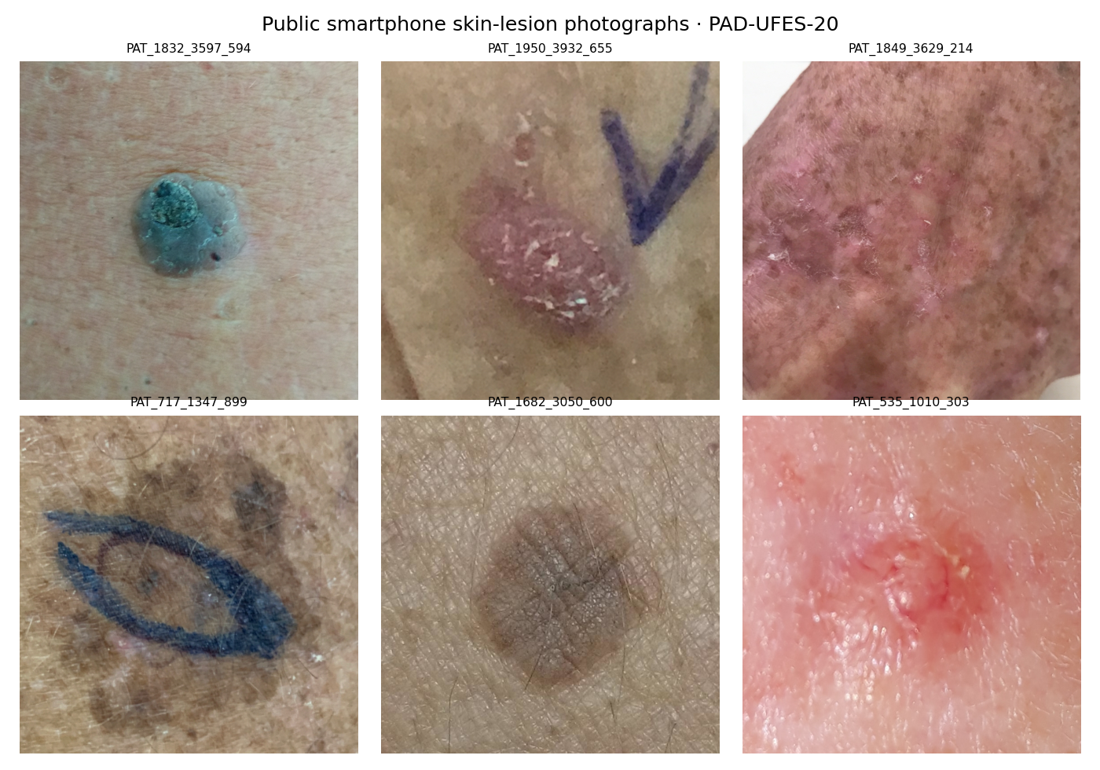

In [2]:
metadata = work / "inputs/metadata.csv"
if not metadata.exists():
    metadata = prepare(work / "inputs")
cohort = pd.read_csv(metadata)
print(cohort.groupby("split").agg(patients=("sample_id", "size"), cancers=("skin_cancer", "sum")))
assert cohort.patient_id.is_unique
show_png(repo / "demos/pad_ufes/inputs.png")


## 2. Freeze the clinical baseline, then fit the image concept space

The original clinical-model paper specifies eight inputs: age, body site, itching, bleeding, pain, growth, change and elevation. Body site is one-hot encoded, giving 22 columns including one unused anatomical-site indicator. Unknown symptom responses remain missing; imputation and scaling use training only. This reconstructs the published inputs and refits coefficients on this cohort; it does not copy a published fitted classifier.

`fit()` extracts actual DINOv3 embeddings, learns an 8,192-entry dictionary with the default Matryoshka levels `[128, 512, 2048, 8192]`, and selects sparsity using validation reconstruction. The default configured search is `[5, 10, 20, 40, 80]`; any failure to reach 0.85 R² is retained as a warning. No parameter is changed after looking at test results.

In [3]:
frozen = freeze_baseline(work)
record = work / "run.json"
if record.exists():
    glyph = Glyph.load_run(Path(json.loads(record.read_text())["run"]), device="cpu")
else:
    glyph = make_glyph(metadata, work / "default_run")
    glyph.fit()
    record.write_text(json.dumps({"run": str(glyph.run_dir)}, indent=2))
    glyph.hypothesis_search()
    glyph.visualize(split="train")
print("Run:", glyph.run_dir.name)
print("Sparsity selection:", glyph.sae_models["image_path"].selection_report)


Run: 20261027T225404Z-c5205f8eac
Sparsity selection: {'dictionary_size': 8192, 'candidate_top_ks': [5, 10, 20, 40, 80], 'r2_targets': [0.85, 0.9, 0.95], 'encoder_initialization': 'training_calibrated_transpose', 'extra_sparsity_per_target': 1.0, 'lookahead_step': 1, 'baseline_top_k': None, 'target_top_k_limits': None, 'selected_top_k': 80, 'selected_validation_r2': 0.7569809260448317, 'reached_minimum': False, 'selected_target': None, 'reason': 'best_reconstruction_below_minimum', 'tried': [{'top_k': 5, 'validation_r2': 0.43482058449199945, 'validation_mse': 0.5702780513928278, 'encoder_initialization_scale': 0.9068206230525043}, {'top_k': 10, 'validation_r2': 0.5309637193205669, 'validation_mse': 0.4732675834239052, 'encoder_initialization_scale': 0.8296148523211433}, {'top_k': 20, 'validation_r2': 0.6084826902272987, 'validation_mse': 0.3950492929808015, 'encoder_initialization_scale': 0.7216226067394101}, {'top_k': 40, 'validation_r2': 0.6878834881098982, 'validation_mse': 0.3149321

## 3. Check saved concepts and association results

Every model selection uses training/validation only. The test set is held out. The complete training-alive concept space is shown, including nonsignificant and untested concepts. Colors denote the strongest corrected training association, not a validated semantic interpretation. Each image evidence page uses training-selected concepts and activation-selected samples with split labels.

In [4]:
print(glyph.phewas_results.groupby("split").size())
for split, data in glyph.embeddings.items():
    restored = glyph.encode_embeddings(data["embeddings"]["image_path"], modality="image_path")
    torch.testing.assert_close(restored, glyph.sae_features["image_path"][split], rtol=0, atol=0)
print("Saved SAE reproduces the exact activations for every split.")
html_path = repo / "demos/pad_ufes/explorer.html"
print("Interactive explorer:", html_path)


split
test     1225
train    5642
val      1183
dtype: int64
Saved SAE reproduces the exact activations for every split.
Interactive explorer: /dataNAS/people/rholland/Glyph/demos/pad_ufes/explorer.html


## 4. Compare with clinical predictors and render the full report

Six numerical prediction arms are retained: literature, literature top 10, Glyph, Glyph top 10, literature + Glyph, and literature + Glyph to 10. Rankings use training only. Validation selects penalties and early-stopping checkpoints, with separate literature/Glyph penalties in combined fits. For this richer clinical pool, `combined_top_n_strategy="pooled"` selects ten total predictors by their training-only ranking across clinical and Glyph candidates. Either or both sources may be selected; the saved source counts show what happened. The compact report omits the full combined row as in the other demos, while keeping it in the CSV exports.

The primary comparison is cancer diagnosis. Test AUC intervals and comparisons use paired patient resampling of frozen predictions. Brackets show exact exploratory, unadjusted p-values and stars. Melanoma has only five test examples and is an underpowered secondary outcome. There is no external validation, automated interpretation or confounder adjustment.

,split,arm,auc,ci_lower,ci_upper
0,test,Literature,0.938874,0.903067,0.966875
1,test,Literature top 10,0.945981,0.914629,0.971015
2,test,Glyph,0.888217,0.842191,0.927689
3,test,Glyph top 10,0.821569,0.761351,0.873419
5,test,Literature + Glyph to 10,0.921877,0.882210,0.954564


{'n_concepts': 1600, 'n_significant_pairs': 164, 'n_comparable_hits': 138, 'n_reproduced_hits': 17}


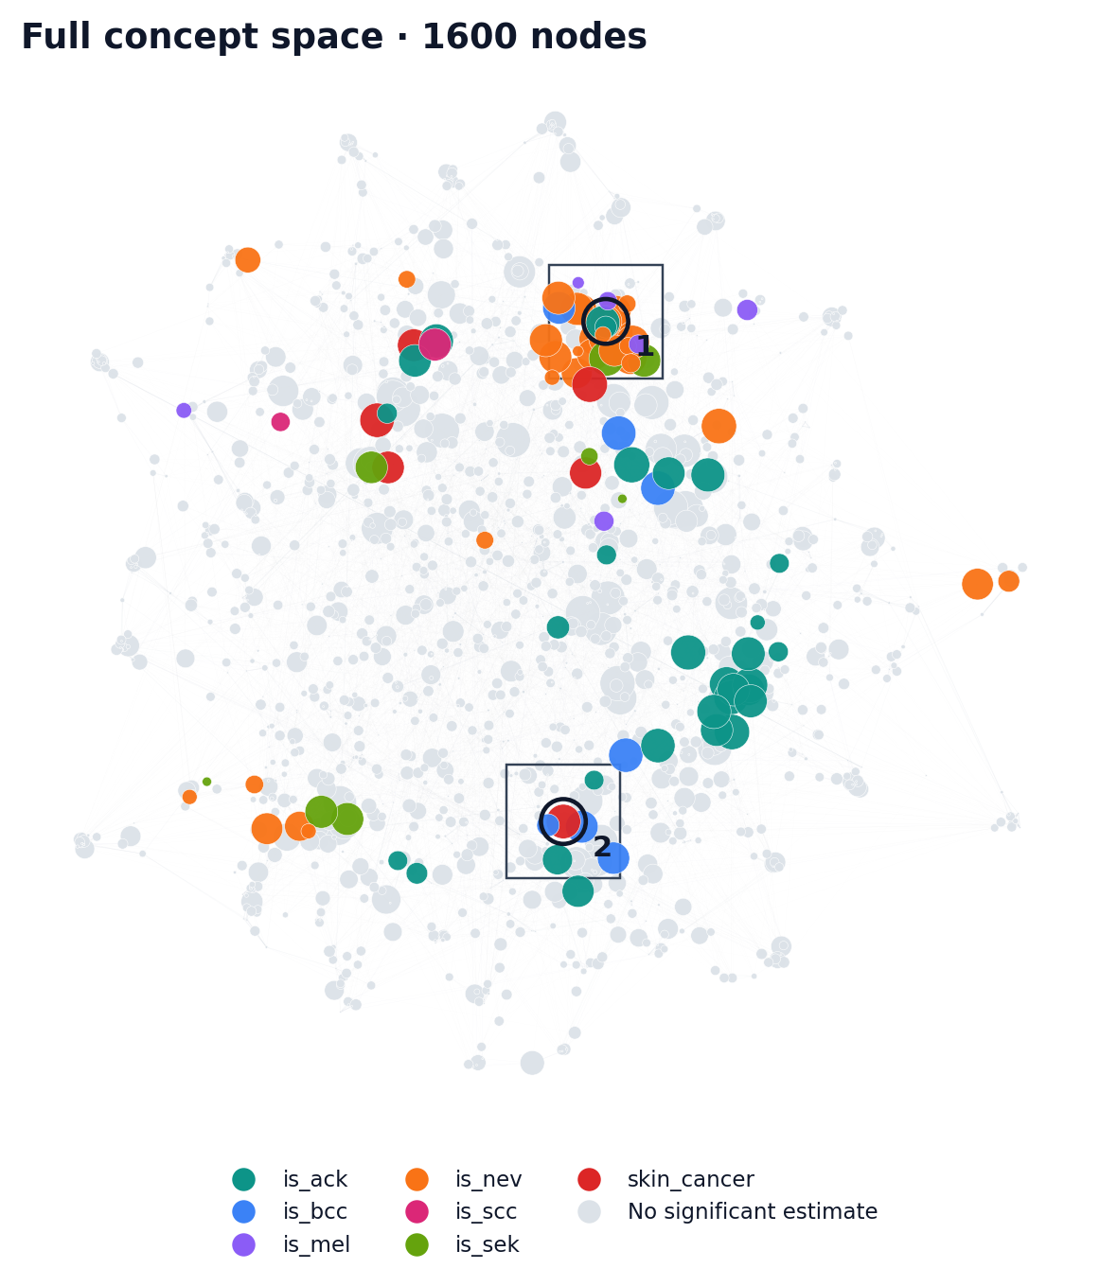

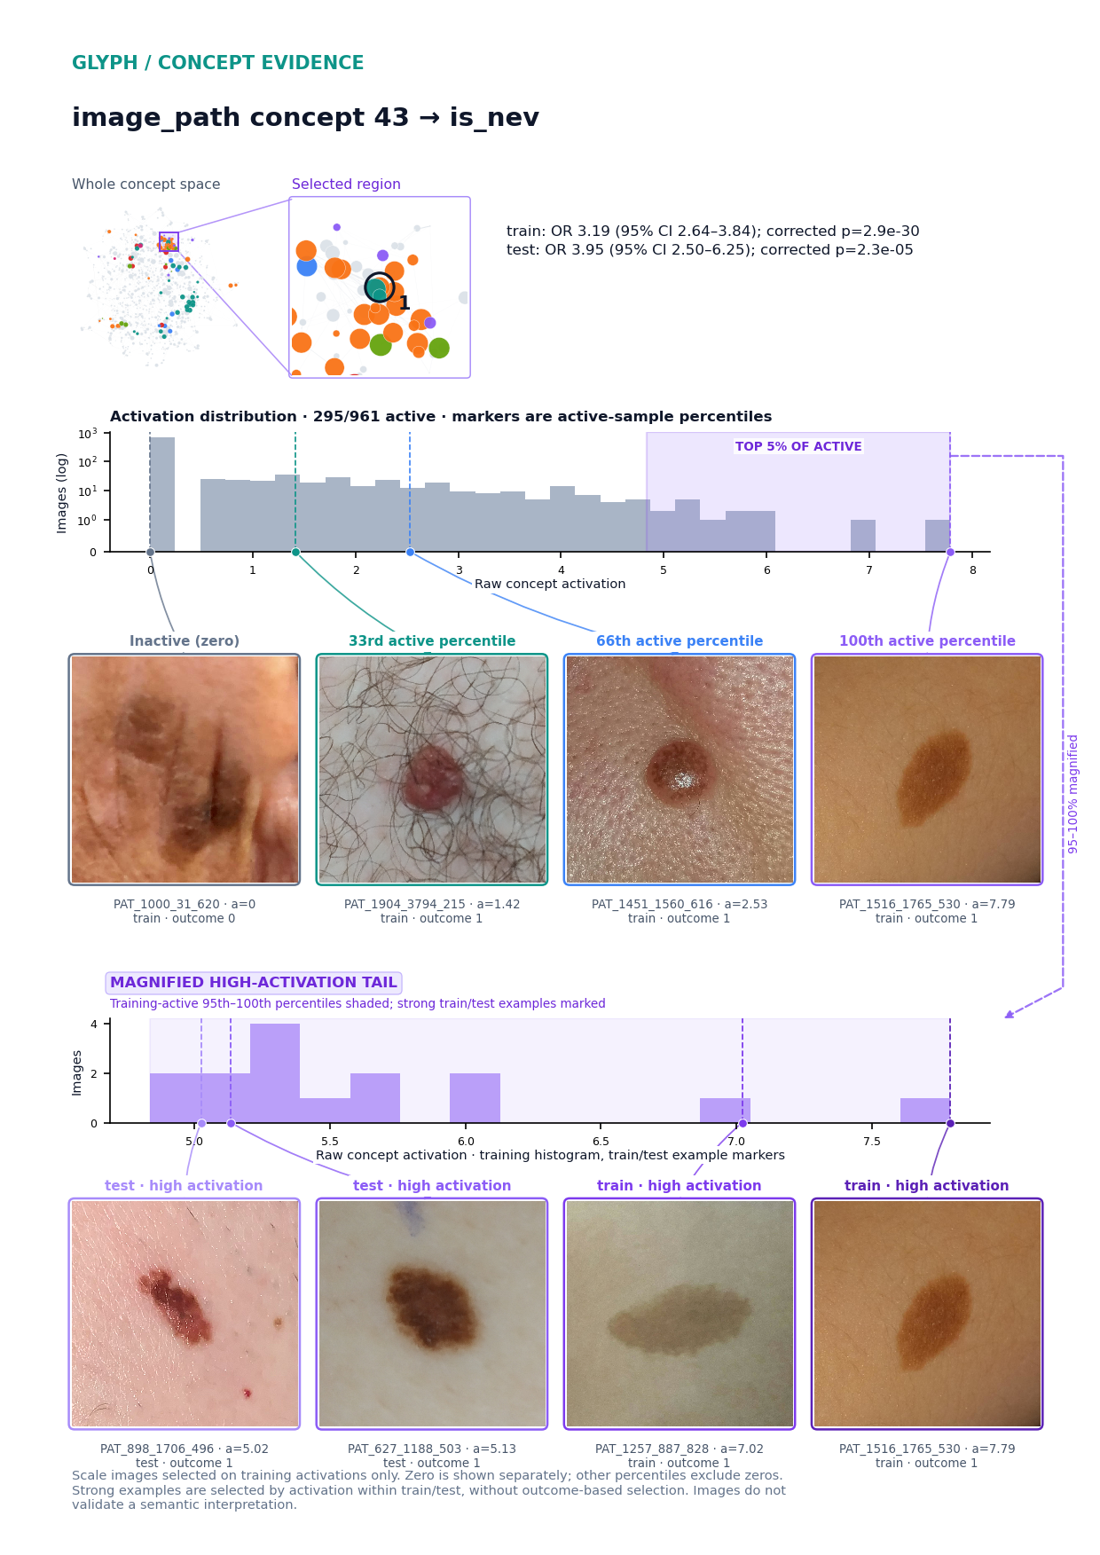

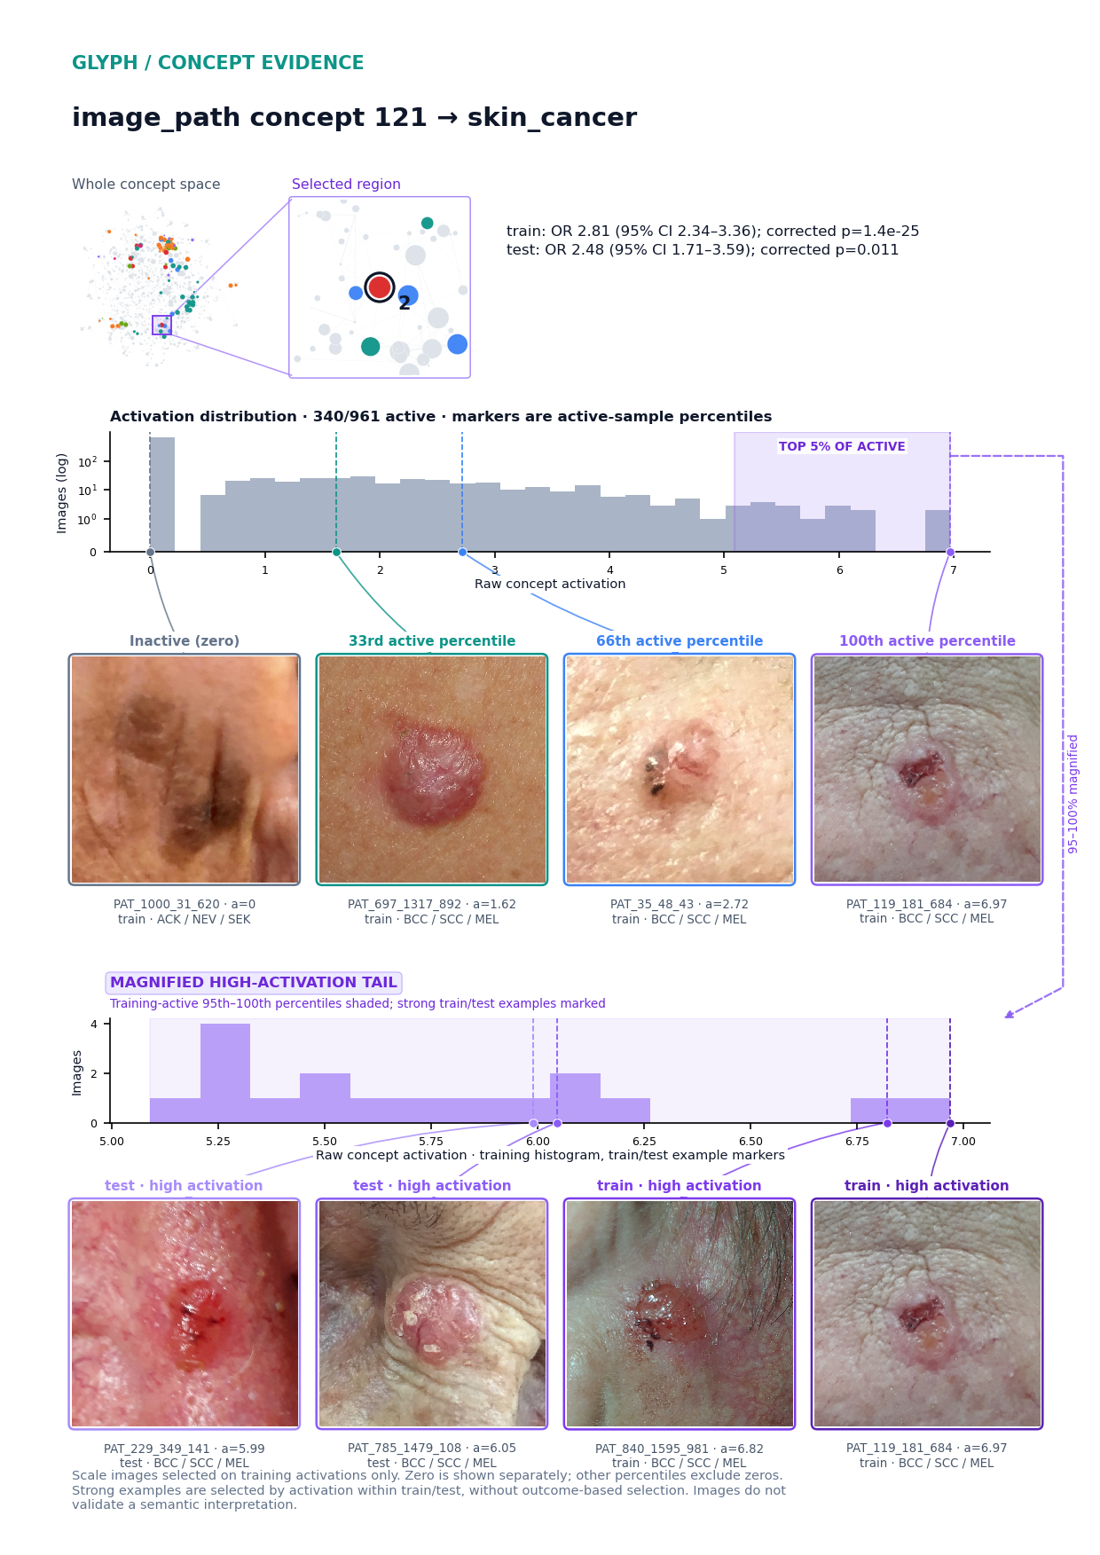

PDF: /dataNAS/people/rholland/Glyph/demos/pad_ufes/report.pdf


In [5]:
study = work / "clinical_comparison/study"
if not (study / "comparison/metrics.csv").exists():
    study = literature_study(glyph, work / "inputs", work / "clinical_comparison", frozen, work / "literature_search")
report_dir = work / "findings_report"
if not (report_dir / "report.pdf").exists():
    report(glyph.run_dir, report_dir, study)
intervals = pd.read_csv(study / "comparison/auc_intervals.csv")
display(intervals[(intervals.split == "test") & intervals.arm.ne("Literature + Glyph")])
facts = json.loads((report_dir / "facts.json").read_text())
print({key: facts[key] for key in ["n_concepts", "n_significant_pairs", "n_comparable_hits", "n_reproduced_hits"]})
show_png(report_dir / "concept_space.png")
for i, item in enumerate(facts["image_examples"]):
    show_png(report_dir / f"concept_{i+1}.png")
print("PDF:", repo / "demos/pad_ufes/report.pdf")
